# Thyroid levels vs. methimazole dose (prototype)

Static matplotlib prototype of the linked-panel timeline, before building it in D3.

- Data: `data/processed/personal.json`. Rerun `python scripts/prepare_personal.py` after editing the CSV.
- Dose convention: each draw's dose is what was being taken at that draw, so the change happened at the previous draw.
- Reference ranges are **typical adult ranges, not the lab's own**. Replace them with the ranges on your lab reports.
- T3 is total T3 in ng/mL.

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

DATA = Path("..") / "data" / "processed" / "personal.json"
d = json.loads(DATA.read_text())

draws = pd.DataFrame(d["draws"])
labs = pd.DataFrame(d["labs"])
dose = pd.DataFrame(d["dose_spans"])
status = pd.DataFrame(d["status_spans"])
for df, cols in [(draws, ["date"]), (labs, ["date"]), (dose, ["start", "end"]), (status, ["start", "end"])]:
    for c in cols:
        df[c] = pd.to_datetime(df[c])

# Typical adult ranges. Replace with the ranges printed on your lab reports.
REF = {"TSH": (0.4, 4.0), "FT4": (0.8, 1.8), "T3": (0.8, 2.0)}
UNITS = {"TSH": "mIU/L", "FT4": "ng/dL", "T3": "total, ng/mL"}

BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#a3a29c"
STATUS_COLORS = {
    "hyperthyroid": "#e34948",
    "subclinical_hyper": "#eda100",
    "euthyroid": "#1baf7a",
    "subclinical_hypo": "#6250d6",
    "hypothyroid": "#2a78d6",
}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Every dose span after the first starts at a dose change; the last span's dose is unknown.
known = dose.dropna(subset=["dose_mg"]).reset_index(drop=True)
changes = known.iloc[1:].assign(prev_mg=known["dose_mg"].shift(1).iloc[1:])
changes[["start", "prev_mg", "dose_mg"]]

,start,prev_mg,dose_mg
1,2024-02-01,0.0,10.0
2,2024-05-20,10.0,0.0
3,2024-06-26,0.0,7.5
4,2024-08-07,7.5,5.0
5,2025-10-21,5.0,2.5
6,2026-05-29,2.5,5.0
7,2026-06-26,5.0,7.5


## 1. Timeline: dose and labs on a shared time axis

Dashed lines mark each dose change and run through every panel.

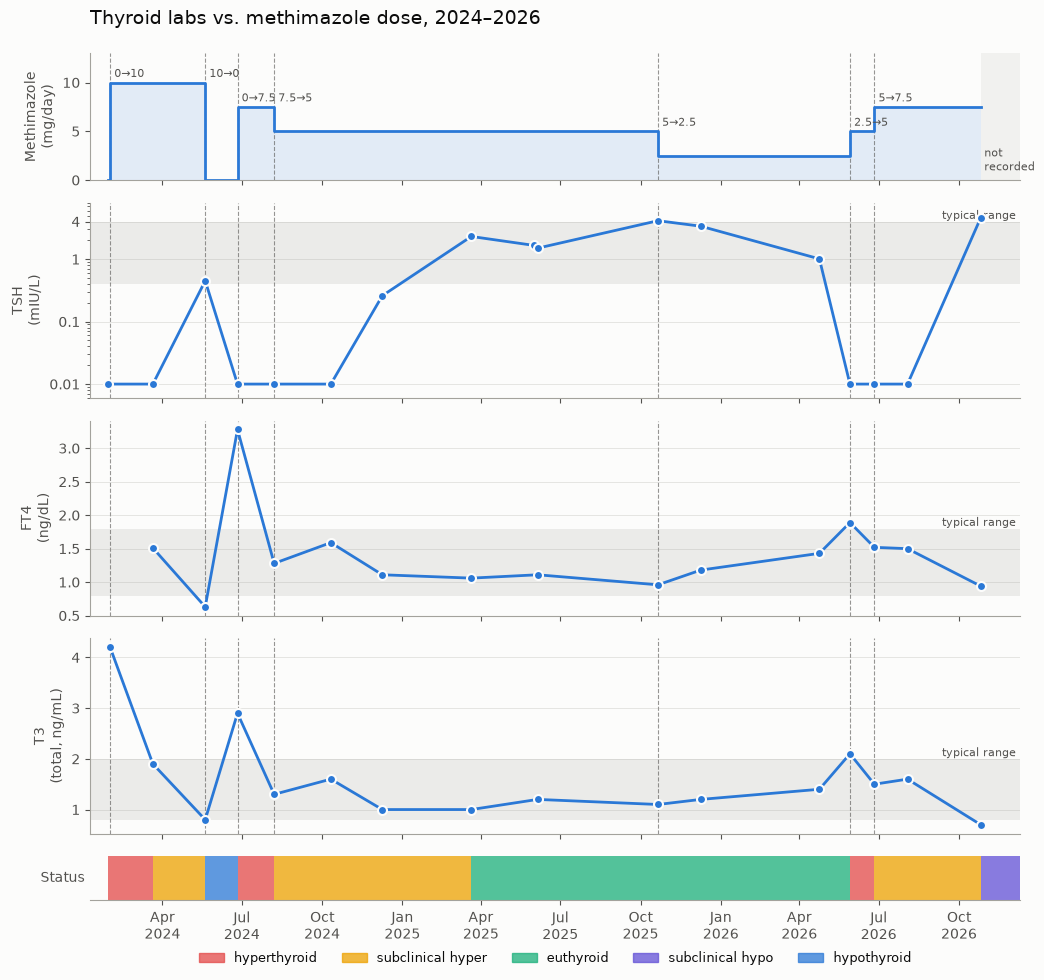

In [2]:
x_end = draws["date"].max() + pd.Timedelta(days=45)

fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True,
                         gridspec_kw={"height_ratios": [1.3, 2, 2, 2, 0.45], "hspace": 0.15})
ax_dose, ax_tsh, ax_ft4, ax_t3, ax_status = axes

# Dose: step line, held at each value until the next change.
xs = list(known["start"]) + [known["end"].iloc[-1]]
ys = list(known["dose_mg"]) + [known["dose_mg"].iloc[-1]]
ax_dose.step(xs, ys, where="post", color=BLUE, lw=2)
ax_dose.fill_between(xs, ys, step="post", color=BLUE, alpha=0.12, lw=0)
ax_dose.axvspan(known["end"].iloc[-1], x_end, color=MUTED, alpha=0.12, lw=0)
ax_dose.text(known["end"].iloc[-1] + pd.Timedelta(days=4), 1, "not\nrecorded", color=INK2, fontsize=8)
for _, c in changes.iterrows():
    ax_dose.annotate(f"{c.prev_mg:g}→{c.dose_mg:g}", (c.start, max(c.prev_mg, c.dose_mg)),
                     xytext=(3, 4), textcoords="offset points", fontsize=8, color=INK2)
ax_dose.set_ylim(0, 13)
ax_dose.set_ylabel("Methimazole\n(mg/day)")


def lab_panel(ax, lab, log=False):
    s = labs[labs["lab"] == lab].sort_values("date")
    if lab in REF:
        lo, hi = REF[lab]
        ax.axhspan(lo, hi, color=MUTED, alpha=0.18, lw=0)
        ax.text(x_end, hi, "typical range ", ha="right", va="bottom", fontsize=8, color=INK2)
    ax.plot(s["date"], s["value"], color=BLUE, lw=2, zorder=2)
    ax.scatter(s["date"], s["value"], s=42, color=BLUE, edgecolor=SURFACE, lw=1.5, zorder=3)
    if log:
        ax.set_yscale("log")
    ax.set_ylabel(f"{lab}\n({UNITS[lab]})")
    ax.grid(axis="y", color=MUTED, alpha=0.3, lw=0.6)


lab_panel(ax_tsh, "TSH", log=True)
ax_tsh.set_ylim(0.006, 8)
ax_tsh.set_yticks([0.01, 0.1, 1, 4])
ax_tsh.set_yticklabels(["0.01", "0.1", "1", "4"])
lab_panel(ax_ft4, "FT4")
lab_panel(ax_t3, "T3")

for ax in axes[:4]:
    for c in changes["start"]:
        ax.axvline(c, color=INK2, ls="--", lw=0.8, alpha=0.6, zorder=1)

# Status strip: each draw's classification held until the next draw.
for _, s in status.iterrows():
    end = s["end"] if pd.notna(s["end"]) else x_end
    ax_status.axvspan(s["start"], end, color=STATUS_COLORS[s["status"]], alpha=0.75, lw=0)
ax_status.set_yticks([])
ax_status.spines["left"].set_visible(False)
ax_status.set_ylabel("Status", rotation=0, ha="right", va="center")
ax_status.legend(handles=[Patch(color=c, alpha=0.75, label=k.replace("_", " ")) for k, c in STATUS_COLORS.items()],
                 loc="upper center", bbox_to_anchor=(0.5, -0.9), ncol=5, frameon=False, fontsize=9)

ax_status.set_xlim(draws["date"].min() - pd.Timedelta(days=20), x_end)
ax_status.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax_status.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle("Thyroid labs vs. methimazole dose, 2024–2026", x=0.125, y=0.92, ha="left", fontsize=14)
fig.savefig("timeline.png", dpi=110, bbox_inches="tight")
plt.show()

## 2. Response after each dose change

Labs replotted by days since each dose change, starting at day 0 (the draw that triggered the change, which still reflects the old dose). Each window ends at the next change. Blue = dose increase, orange = decrease or stop.

In [3]:
bounds = list(changes["start"].iloc[1:]) + [draws["date"].max()]
windows = []
for (_, c), nxt in zip(changes.iterrows(), bounds):
    w = labs[(labs["date"] >= c.start) & (labs["date"] <= nxt) & labs["lab"].isin(["TSH", "FT4"])].copy()
    w["days"] = (w["date"] - c.start).dt.days
    w["change"] = f"{c.start:%Y-%m}: {c.prev_mg:g}→{c.dose_mg:g} mg"
    w["direction"] = "increase" if c.dose_mg > c.prev_mg else "decrease"
    windows.append(w)
resp = pd.concat(windows)
resp.pivot_table(index=["change", "days"], columns="lab", values="value")

lab                      FT4   TSH
change            days            
2024-02: 0→10 mg  49    1.51  0.01
                  109   0.63  0.45
2024-05: 10→0 mg  0     0.63  0.45
                  37    3.28  0.01
2024-06: 0→7.5 mg 0     3.28  0.01
                  42    1.28  0.01
2024-08: 7.5→5 mg 0     1.28  0.01
                  65    1.59  0.01
                  124   1.11  0.26
                  226   1.06  2.31
                  298    NaN  1.66
                  302   1.11  1.50
                  440   0.96  4.13
2025-10: 5→2.5 mg 0     0.96  4.13
                  49    1.18  3.37
                  185   1.43  1.01
                  220   1.89  0.01
2026-05: 2.5→5 mg 0     1.89  0.01
                  28    1.52  0.01
2026-06: 5→7.5 mg 0     1.52  0.01
                  38    1.50  0.01
                  122   0.94  4.63

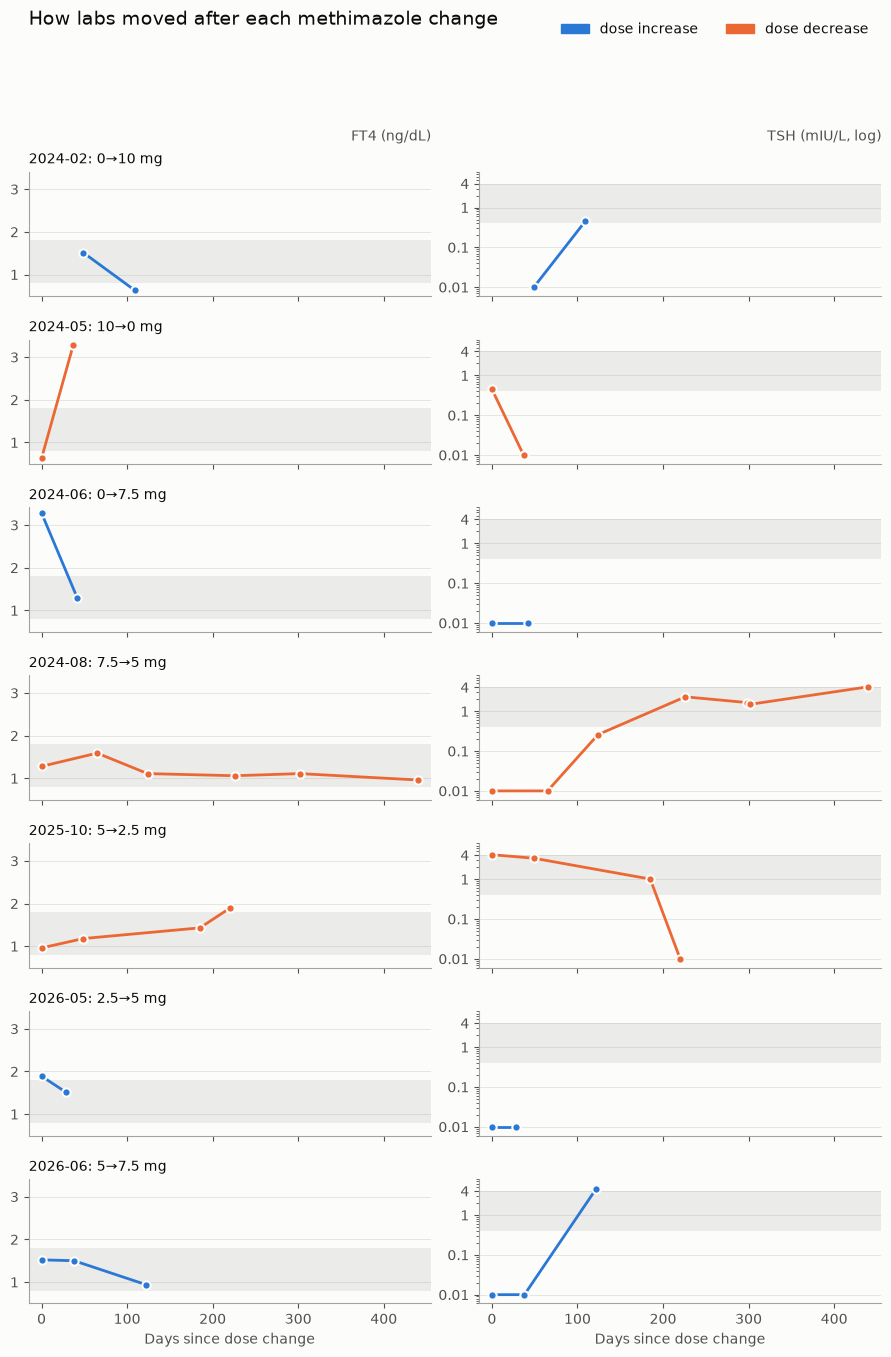

In [4]:
# Small multiples: one row per dose change, shared axes so response speed is comparable.
DIR_COLORS = {"increase": BLUE, "decrease": ORANGE}
groups = list(resp.groupby("change", sort=False))
fig, axes = plt.subplots(len(groups), 2, figsize=(11, 2.1 * len(groups)), sharex=True, sharey="col",
                         gridspec_kw={"hspace": 0.35, "wspace": 0.12})

for row, (change, g) in zip(axes, groups):
    col = DIR_COLORS[g["direction"].iloc[0]]
    for ax, lab in zip(row, ["FT4", "TSH"]):
        lo, hi = REF[lab]
        ax.axhspan(lo, hi, color=MUTED, alpha=0.18, lw=0)
        s = g[g["lab"] == lab].sort_values("days")
        ax.plot(s["days"], s["value"], color=col, lw=2)
        ax.scatter(s["days"], s["value"], s=36, color=col, edgecolor=SURFACE, lw=1.5, zorder=3)
        ax.grid(axis="y", color=MUTED, alpha=0.3, lw=0.6)
    row[0].set_title(change, loc="left", fontsize=10, color=INK)

axes[0, 0].text(1, 1.25, "FT4 (ng/dL)", transform=axes[0, 0].transAxes, ha="right", fontsize=10, color=INK2)
axes[0, 1].text(1, 1.25, "TSH (mIU/L, log)", transform=axes[0, 1].transAxes, ha="right", fontsize=10, color=INK2)
axes[0, 1].set_yscale("log")
axes[0, 1].set_ylim(0.006, 8)
axes[0, 1].set_yticks([0.01, 0.1, 1, 4])
axes[0, 1].set_yticklabels(["0.01", "0.1", "1", "4"])
axes[0, 0].set_xlim(-15, resp["days"].max() + 15)
for ax in axes[-1]:
    ax.set_xlabel("Days since dose change")
fig.legend(handles=[Patch(color=c, label=f"dose {k}") for k, c in DIR_COLORS.items()],
           frameon=False, loc="upper right", bbox_to_anchor=(0.9, 0.99), ncol=2)
fig.suptitle("How labs moved after each methimazole change", x=0.125, y=0.99, ha="left", fontsize=14)
fig.savefig("response.png", dpi=110, bbox_inches="tight")
plt.show()